# Point-supervised segmentation: reconstructed assessment demo

This notebook demonstrates the reconstructed loss and annotation contracts. It is not a campaign result. The original source, manifest and trained checkpoints were not restored. Historical smoke scores and test totals do not certify this implementation.

## Goal
Verify sparse supervision and inspect new run artifacts when they are available. Dataset: LandCover.ai v1; CC BY-NC-SA 4.0; imagery from the Head Office of Geodesy and Cartography, Poland.

## Setup
Run with the project virtual environment and requirements-phase3-cpu.lock. All demonstration arrays below are explicitly synthetic. No training or test inference is triggered by this notebook.

In [1]:
from pathlib import Path
import json
import numpy as np
import torch
import matplotlib.pyplot as plt
from src.losses import PartialCrossEntropyLoss
from src.point_sampling import sample_points
from src.config import load_config
get_ipython().run_line_magic("matplotlib", "inline")
STYLE = {"font.family": "DejaVu Sans", "font.size": 10, "axes.spines.top": False, "axes.spines.right": False}
torch.set_num_threads(4)
torch.manual_seed(17)
plt.rcParams.update(STYLE)
repo = Path.cwd()
assert (repo / "configs/smoke.yaml").is_file()

## Steps
### 1. Check the partial-loss reduction
On a fully selected synthetic mask, Partial CE must equal ordinary CE. When only one pixel is selected, direct gradients at other output pixels must be zero.

In [2]:
logits = torch.randn(2, 5, 8, 8, requires_grad=True)
target = torch.randint(5, (2, 8, 8))
full = torch.ones_like(target, dtype=torch.bool)
partial_ce = PartialCrossEntropyLoss()
full_loss = partial_ce(logits, target, full)
reference = torch.nn.functional.cross_entropy(logits, target)
torch.testing.assert_close(full_loss, reference)
points = torch.zeros_like(full)
points[0, 3, 4] = True
loss = partial_ce(logits, target, points)
loss.backward()
assert torch.count_nonzero(logits.grad.permute(0, 2, 3, 1)[~points]) == 0
print("PASS: full-label equivalence and direct sparse-gradient exclusion")

PASS: full-label equivalence and direct sparse-gradient exclusion


### 2. Inspect class-blind sampling
The 64 × 64 canvas below is synthetic and contains no semantic class information. Both strategies place exactly 50 unique points. Uniform budgets use prefixes of one permutation, so 10/50/200 points are nested for a fixed seed.

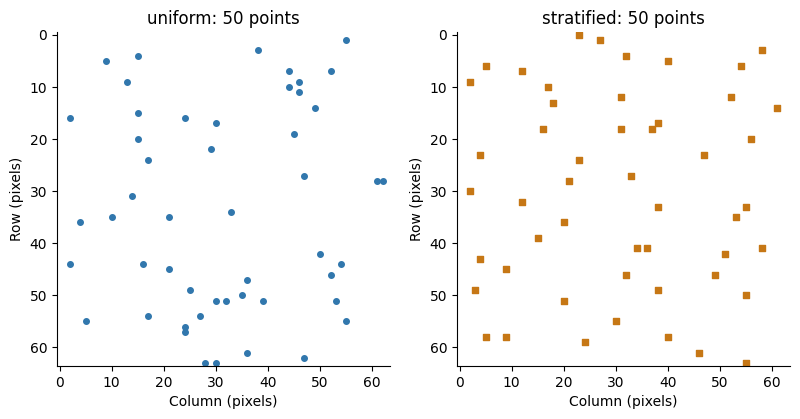

In [3]:
valid = np.ones((64, 64), dtype=bool)
strategies = ["uniform", "stratified"]
fig, axes = plt.subplots(1, 2, figsize=(8, 4), layout="constrained")
for ax, strategy, color in zip(axes, strategies, ["#3177ad", "#c67715"]):
    sampled = sample_points(valid, 50, 17, strategy)
    assert sampled.sum() == 50
    yy, xx = np.nonzero(sampled)
    ax.scatter(xx, yy, s=16, color=color, marker="o" if strategy == "uniform" else "s")
    ax.set(xlim=(-.5, 63.5), ylim=(63.5, -.5), aspect="equal", title=f"{strategy}: 50 points", xlabel="Column (pixels)", ylabel="Row (pixels)")
plt.show()
small = sample_points(valid, 10, 17)
large = sample_points(valid, 200, 17)
assert np.all(~small | large)

## Checks
### 3. Inspect current evidence
These checks report only newly generated files. Absence of real-data evidence is shown explicitly and does not become a passing real-data gate.

In [4]:
for relative in ["results/verification/current_suite.json", "results/verification/real_data_smoke.json"]:
    path = repo / relative
    if path.exists():
        record = json.loads(path.read_text())
        fields = ["status", "passed", "skipped", "real_data", "exact_reload", "scope"]
        print(relative, {k: record[k] for k in fields if k in record})
    else:
        print(f"NOT RUN / NO EVIDENCE: {relative}")
manifest = repo / "data/manifests/splits.json"
if manifest.exists():
    print("Current manifest audit:", json.loads(manifest.read_text())["audit"])
else:
    print("Frozen geographic manifest is unavailable; real-data gate is pending.")

results/verification/current_suite.json {'status': 'passed', 'passed': 114, 'skipped': 1, 'scope': 'reconstructed code; synthetic raster integration, not real-data smoke'}
NOT RUN / NO EVIDENCE: results/verification/real_data_smoke.json
Frozen geographic manifest is unavailable; real-data gate is pending.


### 4. Inspect available smoke curves
A new smoke run is integration evidence only. Its validation scores are not final experimental comparisons.

In [5]:
run = repo / load_config("configs/smoke.yaml")["experiment"]["output_root"] / "uniform_50/seed_17"
history_path = run / "history.json"
if history_path.exists():
    history = json.loads(history_path.read_text())
    fig, ax = plt.subplots(figsize=(7, 3.5), layout="constrained")
    ax.plot([h["epoch"] for h in history], [100 * h["val"]["miou"] for h in history], "o-", color="#3177ad")
    ax.set(xlabel="Epoch", ylabel="Dense validation mIoU (%)", ylim=(0, 100), title="Reconstructed integration smoke only")
    plt.show()
else:
    print("NOT RUN: reconstructed real-data smoke. No scores are substituted.")

NOT RUN: reconstructed real-data smoke. No scores are substituted.


## Next Steps
The mathematical demo validates its own assertions only. The project gate also requires the current test suite, official archive and scene checksum verification, a frozen geographic manifest, real-data training, and exact checkpoint reload. Phase 4 uses the explicit campaign runner after these gates pass. Final test evaluation follows protocol/checkpoint freezing.

Sources: user-supplied recovery checkpoint (2026-10-31); [LandCover.ai official site](https://landcover.ai.linuxpolska.com/); current source and result paths shown above.